# Which Elevator Am I In? — Part 3: Classifiers

MIE1050, Assignment 3. This notebook classifies a ride as **Hart House, MC, Myhal or
Rosebrugh**, using the per-ride features made by `Data_Collector/postprocess.py`. It follows
the Lecture 8 workflow (slide 68): prepare and scale the data, build the models, reduce the
features, compare the models, and test once at the end.

**Run it:** in Colab, use *Runtime → Run all*. It reads the data straight from the public
GitHub repo. Locally it reads `../Data_Collector/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

import keras
from keras import layers

SEED = 0
np.random.seed(SEED)

## Import features and prepare the feature matrix

- `ride_features.csv`: one row per ride; the features plus labels.
- `ride_waveforms.csv`: the same rides as raw launch/brake acceleration traces (the CNN's input).

**Features:** the 15 ranked in the report (§4). Each has a physical reason to differ between
elevators: drive tuning (jerk, rise time, plateaus), motor speed (cruise speed), lamps (light
level and flicker), and rope/cabin dynamics (wobble, sway).

In [2]:
# import features from drive
# (read from the GitHub repo, so Colab and a local copy load the same files)
if os.path.exists("../Data_Collector/ride_features.csv"):      # running inside the repo
    DATA = "../Data_Collector/"
else:                                                          # running in Colab
    DATA = "https://raw.githubusercontent.com/chrystalight/PATTERN-RECOGNITION/main/Data_Collector/"

features = pd.read_csv(DATA + "ride_features.csv")
waveforms = pd.read_csv(DATA + "ride_waveforms.csv")
assert (features[["session", "ride"]].values == waveforms[["session", "ride"]].values).all()


# prepare feature matrix
FEATURES = [
    "accel_rise_s", "launch_jerk_g_s", "launch_accel_g", "brake_jerk_g_s", "light_mean",
    "cruise_speed_mps", "launch_plateau_s", "accel_decel_ratio", "light_flicker_index",
    "launch_phase_s", "post_stop_wobble_g", "brake_release_s", "brake_accel_g",
    "peak_jerk_g_s", "sway_rest_ratio",
]
SHORT = {"Hart House": "Hart House", "Mechanical (MC)": "MC", "Myhal": "Myhal", "Rosebrugh": "Rosebrugh"}
CLASSES = list(SHORT)

print(features.groupby("building").agg(rides=("ride", "size"), sessions=("session", "nunique")))

                 rides  sessions
building                        
Hart House          33         5
Mechanical (MC)     37         2
Myhal               26         2
Rosebrugh           48         7


## Normalize data

Following Lecture 8 slide 29, every feature is **min–max scaled to 0–1**. Otherwise a
large-valued feature like light (~700) would swamp a small one like jerk (~0.05) in KNN's
distance.

The scaler is *learned* from data (each feature's min and max), so it must be fitted on the
training rides only. It goes inside each model as the first step of a `Pipeline`, and is
refitted every time the model is trained. Naive Bayes, the trees and the CNN don't need it:
the first two treat each feature on its own scale, and the CNN divides its input by the
training standard deviation itself.

In [3]:
# normalize data
def scaled(model):
    # min-max scaling (fitted on the training rides only), then the model
    return make_pipeline(MinMaxScaler(), model)

## Split training, validation and test

Lecture 8 slide 22 uses three data sets: **training**, **verification** (validation) and
**test**.

**Test:** we are keeping one extra session per building back. Once the model is frozen, add
those sessions to the repo, re-run `postprocess.py`, and list their folder names in
`HOLDOUT_SESSIONS`. The last section scores them once. Nothing before it uses them.

**Training / validation = cross-validation, leave-one-session-out (LOSO).** Rides in the same
recording session are near-copies of each other (same day, same board placement). A random
split would put near-copies on both sides and inflate the accuracy; Lecture 8 slide 58 shows
the same effect (99.4% out-of-bag vs 97.0% on new days). So, for each of the 16 sessions:
1. Train a fresh model on all *other* sessions.
2. Predict the rides in the left-out session.

Every ride is predicted exactly once, by a model that never saw its session. Myhal has two
sessions, one per car. So LOSO trains Myhal on one car and tests on the other, which checks
that the classifier learns the *building*, not the car.

In [4]:
# split training, validation, test, cross validation?
HOLDOUT_SESSIONS = []     # e.g. ["2026-11-05_120000_Myhal_left", ...] -- fill in only at the very end

is_test = features["session"].isin(HOLDOUT_SESSIONS).to_numpy()
dev = features[~is_test]                  # training + validation rides
X = dev[FEATURES].to_numpy()
y = dev["building"].to_numpy()
groups = dev["session"].to_numpy()        # LOSO splits on this
print(f"{len(dev)} rides for training/validation, {is_test.sum()} held out for the final test")


def loso_predict(make_model, X, y, groups):
    # Leave-one-session-out: each session is predicted by a model trained on all the others.
    # make_model is a function that BUILDS a new, untrained model. We pass a builder rather than a
    # model because every fold needs a fresh one that has never seen any data; reusing one model
    # would carry what it learned in earlier folds (including the left-out session) into later ones.
    predictions = np.empty(len(y), dtype=object)                 # one predicted building per ride
    for train, test in LeaveOneGroupOut().split(X, y, groups):   # row numbers; test = one whole session
        model = make_model()                                     # fresh, untrained model
        model.fit(X[train], y[train])                            # learn from the other sessions only
        predictions[test] = model.predict(X[test])               # predict the left-out session
    return predictions


results = {}      # model name -> LOSO predictions, filled in by each section


def report(name, predictions):
    results[name] = predictions
    print(f"{name}: LOSO accuracy = {accuracy_score(y, predictions):.1%}")

144 rides for training/validation, 0 held out for the final test


In [5]:
'''

 Implement KNN, naive Bayes, 1D CNN and a decision tree or random forest.

 Compare them with a simple heuristic baseline, such as a threshold on peak acceleration.

 Apply PCA or wrapper feature selection, and report which features survive.

'''

'\n\n Implement KNN, naive Bayes, 1D CNN and a decision tree or random forest.\n\n Compare them with a simple heuristic baseline, such as a threshold on peak acceleration.\n\n Apply PCA or wrapper feature selection, and report which features survive.\n\n'

## KNN (Lecture 8 slides 26–32)

- Euclidean distance on the scaled features; the class is the most common class among the K
  nearest rides.
- **K must be odd** (slide 28). We try K = 1, 3, …, 15 and keep the best. If several tie, we keep
  the largest, which is more stable than K = 1 (slide 31). (Picking K with the same LOSO scores
  makes the KNN number slightly optimistic.)

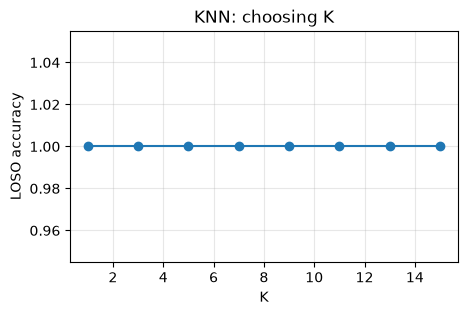

KNN (K=15): LOSO accuracy = 100.0%


In [6]:
# KNN
def make_knn(k):
    return scaled(KNeighborsClassifier(n_neighbors=k))


# `lambda: make_knn(k)` is a tiny unnamed function that takes no inputs and returns make_knn(k).
# loso_predict needs a model *builder* (see above), and this is the shortest way to hand it one
# with K already filled in. The same pattern is used for the other models below.
k_values = range(1, 16, 2)                                       # odd K only: 1, 3, ..., 15
k_accuracy = [accuracy_score(y, loso_predict(lambda: make_knn(k), X, y, groups)) for k in k_values]
BEST_K = max(k for k, acc in zip(k_values, k_accuracy) if acc == max(k_accuracy))   # ties -> largest K

plt.figure(figsize=(5, 3))
plt.plot(list(k_values), k_accuracy, "o-")
plt.xlabel("K"); plt.ylabel("LOSO accuracy"); plt.title("KNN: choosing K"); plt.grid(alpha=0.3)
plt.show()

report(f"KNN (K={BEST_K})", loso_predict(lambda: make_knn(BEST_K), X, y, groups))

## Naive Bayes (Lecture 8 slides 33–48)

- Bayes' theorem per class. The features are assumed independent ("naive"), so the
  per-feature probabilities multiply. The class with the highest product wins.
- The lecture bins each feature into levels (slow … fast). **Gaussian** naive Bayes is the
  continuous version: it fits a normal curve per class and feature in place of the bin counts.
- **Equal priors** (1/4 each), as in the lecture's elevator example ("assume all elevators are
  visited the same number of times"), so having more Rosebrugh rides doesn't bias it.
- Caveat: several of our features are strongly correlated (rise time, jerk and launch phase,
  r ≈ 0.9). That breaks the independence assumption; feature selection (below) removes the
  redundancy.

In [7]:
# naive Bayes
def make_nb():
    return GaussianNB(priors=[0.25] * 4)


report("Naive Bayes", loso_predict(make_nb, X, y, groups))

Naive Bayes: LOSO accuracy = 68.1%


## 1D CNN

The CNN is the one model not covered in Lecture 8 (slide 5 only says deep learning "learns
higher-level features from the raw input"). So it gets the **raw signal**, not our features:
- The vertical acceleration (1.5 Hz low-pass) from 1 s before the launch to 3 s after it, and
  from 3 s before the stop to 1 s after it.
- Two channels of 100 samples (25 Hz), signed so the launch is positive in both directions.

The network is kept tiny because there are only ~140 rides: two small convolution layers, an
average over time, and a softmax over the four buildings. The traces are divided by the
training rides' standard deviation, so the inputs are about unit size.

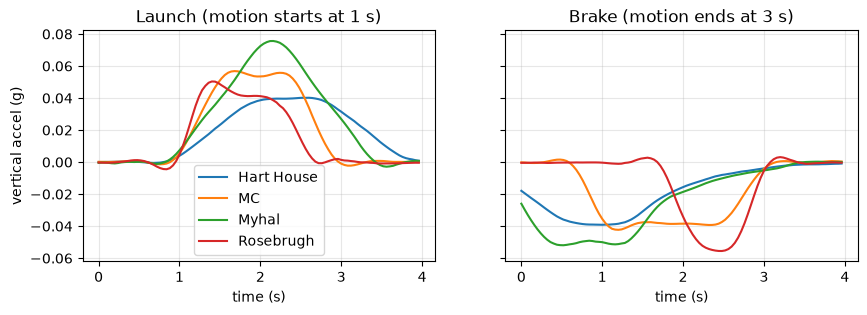

1D CNN: LOSO accuracy = 100.0%


In [8]:
# 1D CNN
launch_cols = [c for c in waveforms.columns if c.startswith("launch_")]
brake_cols = [c for c in waveforms.columns if c.startswith("brake_")]
# Each ride becomes a 100 x 2 array: 100 time samples (4 s at 25 Hz), 2 channels (launch, brake).
# np.stack(..., axis=-1) puts the two (rides x 100) tables side by side as the last dimension,
# giving the (rides, time, channels) shape that Keras' Conv1D expects.
W = np.stack([waveforms[launch_cols].to_numpy(), waveforms[brake_cols].to_numpy()], axis=-1)
W_dev = W[~is_test]                                     # shape (rides, 100 samples, 2 channels)

# what the CNN sees: the median trace per building
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
t = np.arange(W.shape[1]) / 25.0
for c in CLASSES:
    for ch, ax in enumerate(axes):
        ax.plot(t, np.median(W_dev[y == c, :, ch], axis=0), label=SHORT[c])
axes[0].set_title("Launch (motion starts at 1 s)"); axes[1].set_title("Brake (motion ends at 3 s)")
axes[0].set_ylabel("vertical accel (g)"); axes[0].legend()
for ax in axes:
    ax.set_xlabel("time (s)"); ax.grid(alpha=0.3)
plt.show()


class CNN:
    # Small 1D CNN with the same fit / predict interface as the scikit-learn models.

    def fit(self, W, y):
        keras.utils.set_random_seed(SEED)              # same starting weights every run -> repeatable
        self.scale = W.std()                           # training spread; inputs become ~unit size
        self.classes = np.unique(y)                    # the 4 building names, sorted
        self.model = keras.Sequential([
            keras.Input(shape=W.shape[1:]),            # one ride: 100 samples x 2 channels
            # 8 learned pattern detectors, each 5 samples (0.2 s) wide, slid along the trace;
            # each outputs how strongly its shape (e.g. a steep ramp) appears at every moment
            layers.Conv1D(8, kernel_size=5, activation="relu"),
            layers.MaxPooling1D(2),                    # keep the larger of each pair of samples: halves the length
            # 16 detectors that look for combinations of the first layer's patterns
            layers.Conv1D(16, kernel_size=5, activation="relu"),
            layers.GlobalAveragePooling1D(),           # average each detector over time -> 16 numbers per ride
            layers.Dense(len(self.classes), activation="softmax"),   # 16 numbers -> 4 probabilities (sum to 1)
        ])
        # adam = the standard weight-update method; the loss measures how wrong the probabilities are
        self.model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")
        labels = np.searchsorted(self.classes, y)      # the network needs numbers: building name -> 0..3
        # epochs = passes over all the training rides; batch_size = rides per weight update
        self.model.fit(W / self.scale, labels, epochs=200, batch_size=16, verbose=0)
        return self

    def predict(self, W):
        probabilities = self.model(W / self.scale).numpy()      # (rides, 4) probabilities
        return self.classes[probabilities.argmax(axis=1)]       # most likely building per ride


report("1D CNN", loso_predict(CNN, W_dev, y, groups))

## Decision tree and random forest (Lecture 8 slides 49–58)

- **Decision tree:** splits are chosen greedily to maximise information gain, using
  `criterion="entropy"` as in the lecture.
- **Random forest:** 100 trees. Each tree is trained on a bootstrap sample, each split may use
  only a random subset of the features (√15 ≈ 4), and the trees take a majority vote. Like
  slide 58, we report the feature importances.

Decision tree: LOSO accuracy = 99.3%


Random forest: LOSO accuracy = 100.0%


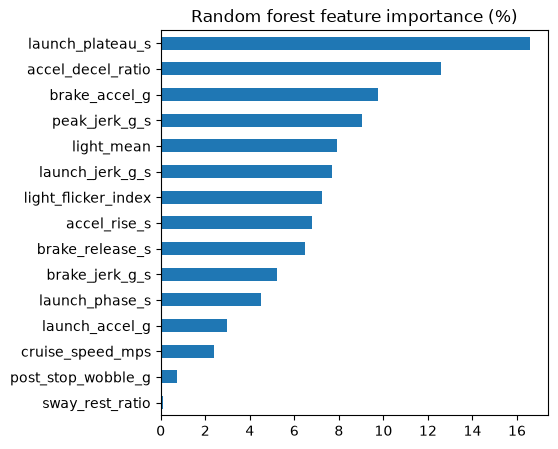

In [9]:
# decision tree/random forest
def make_tree():
    return DecisionTreeClassifier(criterion="entropy", random_state=SEED)


def make_forest():
    return RandomForestClassifier(n_estimators=100, criterion="entropy", max_features="sqrt",
                                  random_state=SEED)


report("Decision tree", loso_predict(make_tree, X, y, groups))
report("Random forest", loso_predict(make_forest, X, y, groups))

forest = make_forest().fit(X, y)
importance = pd.Series(forest.feature_importances_ * 100, index=FEATURES).sort_values()
importance.plot.barh(figsize=(5, 5), title="Random forest feature importance (%)")
plt.show()

## Simple heuristic: a threshold on peak acceleration

This is the assignment's suggested baseline (Lecture 8 slide 13: a heuristic is a hand-set
rule, "any value greater than x is classified as R"). It uses **one feature**, the launch
(peak) acceleration:
- Sort the four buildings by their median value in the training sessions.
- Put a threshold halfway between each pair of neighbours.
- A new ride is classified by which interval it falls in.

In [10]:
# simple heuristic
class ThresholdBaseline:
    # One-feature rule: thresholds halfway between neighbouring class medians.

    def fit(self, X, y):
        x = X[:, 0]                                                   # the single feature
        medians = {c: np.median(x[y == c]) for c in np.unique(y)}     # typical value per building
        self.order = sorted(medians, key=medians.get)                 # buildings from low to high
        m = np.array([medians[c] for c in self.order])
        self.thresholds = (m[:-1] + m[1:]) / 2                        # halfway between neighbours: 3 thresholds
        return self

    def predict(self, X):
        # np.searchsorted counts how many thresholds each value is above (0, 1, 2 or 3). That count
        # is the position of its interval, i.e. the index of its building in self.order.
        return np.array(self.order)[np.searchsorted(self.thresholds, X[:, 0])]


X_peak = dev[["launch_accel_g"]].to_numpy()
report("Baseline (peak accel)", loso_predict(ThresholdBaseline, X_peak, y, groups))

rule = ThresholdBaseline().fit(X_peak, y)
print("\nRule fitted on all sessions:")
for c, t in zip(rule.order, list(rule.thresholds) + [None]):
    print(f"  {SHORT[c]:10s}" + (f" if launch accel < {t:.4f} g" if t is not None else " otherwise"))

Baseline (peak accel): LOSO accuracy = 93.1%

Rule fitted on all sessions:
  Hart House if launch accel < 0.0453 g
  Rosebrugh  if launch accel < 0.0536 g
  MC         if launch accel < 0.0663 g
  Myhal      otherwise


## How correlated are the features?

Correlation (r, from −1 to +1) measures how much two features move together. Two features with
|r| near 1 carry the same information, so the second adds little. We look at it two ways:

- **Across all rides (left):** do two features rank the buildings the same way? With only four
  buildings, any two features that both separate buildings tend to look correlated here, even when
  they are physically unrelated. Launch plateau vs light flicker is a coincidence of how the four
  buildings happen to be ordered.
- **Within buildings (right):** subtract each building's mean first, then correlate what is left:
  the ride-to-ride variation for the same elevator. A high r here means two features share the
  same physics or the same noise. They really are one measurement.

The features are ordered so that related ones sit next to each other.

Some high values within buildings come from known effects rather than duplicate measurements:
- Rosebrugh's up and down rides differ in both cruise speed and brake acceleration.
- Myhal's two cars differ in both light level and flicker.

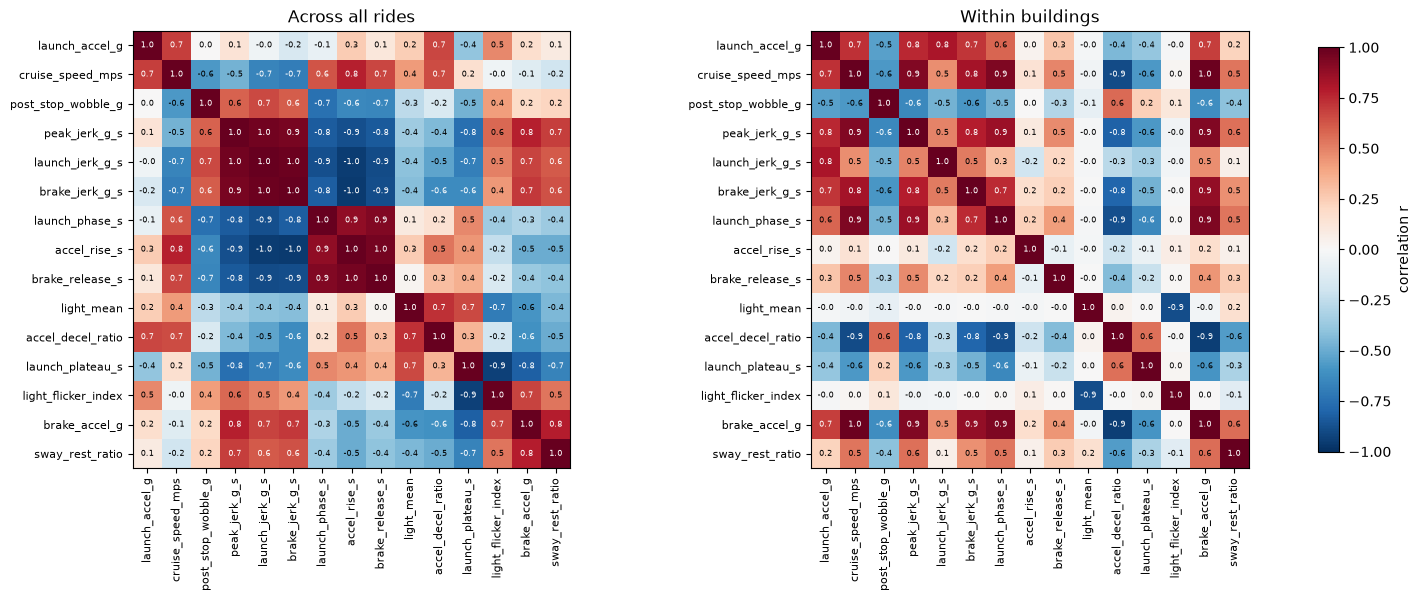

       feature 1           feature 2  r across rides  r within buildings
 launch_jerk_g_s      brake_jerk_g_s            0.98                0.52
 launch_jerk_g_s       peak_jerk_g_s            0.97                0.50
    accel_rise_s      brake_jerk_g_s           -0.96                0.17
    accel_rise_s     brake_release_s            0.96               -0.07
    accel_rise_s     launch_jerk_g_s           -0.95               -0.20
  brake_jerk_g_s       peak_jerk_g_s            0.95                0.78
launch_plateau_s light_flicker_index           -0.93                0.02
  launch_phase_s     brake_release_s            0.93                0.41
 launch_jerk_g_s     brake_release_s           -0.89                0.21
    accel_rise_s      launch_phase_s            0.89                0.24


In [11]:
# feature correlation: across all rides vs within buildings
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

across = dev[FEATURES].corr()
within = (dev[FEATURES] - dev.groupby("building")[FEATURES].transform("mean")).corr()

# order the features so strongly related ones (high |r| across rides) end up next to each other
links = hierarchy.linkage(squareform(1 - across.abs().to_numpy(), checks=False), "average")
order = [FEATURES[i] for i in hierarchy.leaves_list(links)]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"wspace": 0.55})
for ax, (title, corr) in zip(axes, [("Across all rides", across), ("Within buildings", within)]):
    c = corr.loc[order, order]
    image = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8)
    ax.set_yticks(range(len(order)), order, fontsize=8)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{c.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(c.iloc[i, j]) > 0.6 else "black")
    ax.set_title(title)
fig.colorbar(image, ax=axes, shrink=0.7, label="correlation r")
plt.savefig("feature_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

# the pairs that duplicate each other most
pairs = [(a, b, across.loc[a, b], within.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]]
pairs = pd.DataFrame(pairs, columns=["feature 1", "feature 2", "r across rides", "r within buildings"])
print(pairs.reindex(pairs["r across rides"].abs().sort_values(ascending=False).index).head(10)
      .round(2).to_string(index=False))

## Wrapper feature selection: which features survive (Lecture 8 slide 61)

**Forward** wrapper selection:
1. Start with no features.
2. Add whichever feature most improves the classifier's validation accuracy.
3. Stop when the next feature adds less than 1%.

It is a wrapper because each candidate subset is scored by training and testing the actual
classifier.

- **Which features survive:** we run the selection on all training sessions, scoring each
  subset with LOSO.
- **How well the reduced models do:** the selection itself must be repeated inside every LOSO
  fold, so the left-out session never influences which features are chosen. Inside the fold
  it uses a 5-fold split of the training rides.

We do this for KNN and naive Bayes, the two models hurt most by redundant, correlated
features. (Trees choose their own features at each split.)

In [12]:
# wrapper feature selection
loso_splits = list(LeaveOneGroupOut().split(X, y, groups))


def surviving_features(estimator):
    # direction="forward": start empty and add one feature at a time
    # n_features_to_select="auto" with tol=0.01: keep adding until the next feature gains < 1% accuracy
    # cv=loso_splits: each candidate subset is scored with leave-one-session-out
    selector = SequentialFeatureSelector(estimator, direction="forward", n_features_to_select="auto",
                                         tol=0.01, cv=loso_splits)
    selector.fit(X, y)
    # get_support() gives one True/False per feature: True = kept
    return [f for f, keep in zip(FEATURES, selector.get_support()) if keep]


def with_selection(estimator):
    # Selection as the first step of the model, so loso_predict reruns it inside every fold and the
    # left-out session never influences which features are chosen. Inside a fold, subsets are
    # scored with a 5-fold split of the training rides (cv=5).
    return make_pipeline(SequentialFeatureSelector(estimator, direction="forward",
                                                   n_features_to_select="auto", tol=0.01, cv=5),
                         estimator)


for name, estimator in [("KNN", make_knn(BEST_K)), ("Naive Bayes", make_nb())]:
    print(f"{name} keeps: {surviving_features(estimator)}")

report(f"KNN (K={BEST_K}) + selection", loso_predict(lambda: with_selection(make_knn(BEST_K)), X, y, groups))
report("Naive Bayes + selection", loso_predict(lambda: with_selection(make_nb()), X, y, groups))

KNN keeps: ['launch_jerk_g_s']


Naive Bayes keeps: ['launch_jerk_g_s']


KNN (K=15) + selection: LOSO accuracy = 100.0%


Naive Bayes + selection: LOSO accuracy = 100.0%


## Final model: KNN on launch jerk + light flicker

Wrapper selection keeps one feature, **launch jerk**: how fast the car's acceleration builds as it
departs. Each building's drive controller is tuned differently, so it holds across cars, days and
directions.

We add a second feature from a **different sensor** as a backup. A jostled cabin (people
shifting or jumping) disturbs every accelerometer feature at once, so another accelerometer
feature would fail at the same moment. **Light flicker** is the lamp ripple seen by the light sensor:
- It is uncorrelated with jerk.
- It splits the buildings into two pairs: no flicker in Hart House or MC, and always flicker
  in Myhal and Rosebrugh.
- Jerk separates the two buildings within each pair (scatter plot below).

The final model is KNN (min–max scaled, K as chosen above) on these two features. It is small
enough to run on the board.

Correlation of jerk and flicker within buildings: r = -0.03

Final: KNN on jerk + flicker: LOSO accuracy = 100.0%


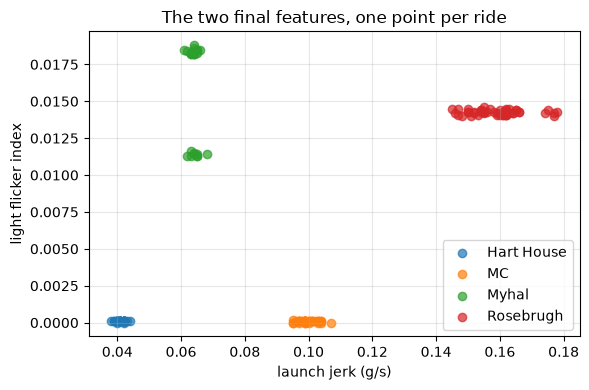

In [13]:
# final model: launch jerk + light flicker
FINAL_FEATURES = ["launch_jerk_g_s", "light_flicker_index"]
X_final = dev[FINAL_FEATURES].to_numpy()


def make_final():
    return make_knn(BEST_K)


# within-building correlation: subtract each building's mean first, so the gap BETWEEN buildings
# doesn't count; what is left shows whether the two features vary together for the same elevator
within = dev[FINAL_FEATURES] - dev.groupby("building")[FINAL_FEATURES].transform("mean")
print(f"Correlation of jerk and flicker within buildings: r = {within.corr().iloc[0, 1]:.2f}\n")

report("Final: KNN on jerk + flicker", loso_predict(make_final, X_final, y, groups))

plt.figure(figsize=(6, 4))
for c in CLASSES:
    rides = dev[y == c]
    plt.scatter(rides["launch_jerk_g_s"], rides["light_flicker_index"], label=SHORT[c], alpha=0.7)
plt.xlabel("launch jerk (g/s)"); plt.ylabel("light flicker index")
plt.title("The two final features, one point per ride"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("final_features.png", dpi=120)
plt.show()

## Comparison

LOSO accuracy for every model, then the confusion matrices (rows = true building,
columns = predicted). The diagonal holds the correct predictions.

KNN (K=15)                      100.0%
Naive Bayes                      68.1%
1D CNN                          100.0%
Decision tree                    99.3%
Random forest                   100.0%
Baseline (peak accel)            93.1%
KNN (K=15) + selection          100.0%
Naive Bayes + selection         100.0%
Final: KNN on jerk + flicker    100.0%


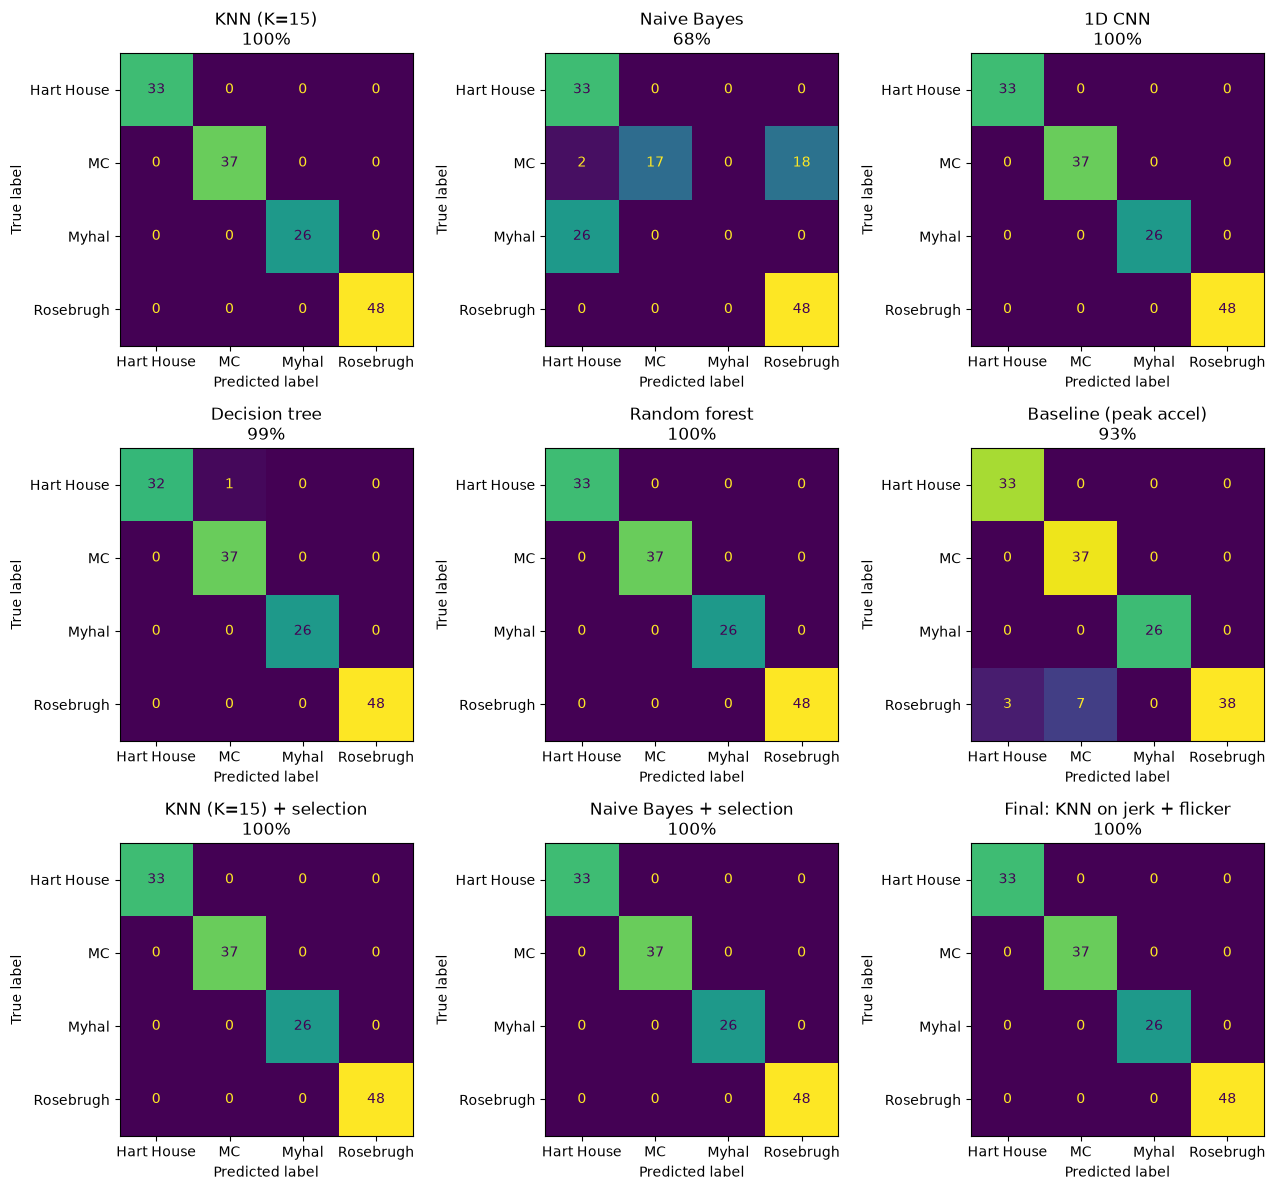

In [14]:
# compare all models
summary = pd.Series({name: accuracy_score(y, p) for name, p in results.items()}, name="LOSO accuracy")
print(summary.map("{:.1%}".format).to_string())

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, (name, p) in zip(axes.flat, results.items()):
    ConfusionMatrixDisplay.from_predictions(y, p, labels=CLASSES, display_labels=list(SHORT.values()),
                                            ax=ax, colorbar=False)
    ax.set_title(f"{name}\n{accuracy_score(y, p):.0%}")
for ax in axes.flat[len(results):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=120)
plt.show()

**Reading the results**
- The rides separate cleanly. Several models reach ~100% LOSO; a single feature (launch jerk)
  is enough for KNN and naive Bayes, and the final two-feature model (jerk + flicker) also
  scores 100%.
- **Naive Bayes on all 15 features fails** on the two buildings with only two sessions (Myhal,
  MC). With one session left out, only one session of that building remains for training. Its
  per-feature normal curves come out very narrow, and the other session (for Myhal, the other
  car, whose lights are brighter) lands in their tails. Fifteen multiplied probabilities then
  hand the ride to another building. Removing the redundant features fixes it.
- The peak-acceleration baseline is already strong (~93%). Every one of its errors is a
  Rosebrugh ride. Rosebrugh's launch acceleration depends on direction (it is probably
  hydraulic), so its range (0.045–0.056 g) runs into MC's (0.055–0.059 g) and nearly reaches
  Hart House's (≤ 0.042 g).

## Export the final model for the board (Part 4)

KNN has no weights to train: "the model" is the training rides themselves. This cell writes them
into a C++ header, `knn_model.h`, which the firmware (`ElevatorLogger_v2/classifier.h`) includes.
It contains:
- every training ride's two feature values and its building;
- the min/max used for scaling, and K;
- for the cross-check: each building's median jerk, whether it has flicker, and the flicker
  threshold between the two pairs.

Re-run this cell whenever the training data changes, then re-upload the firmware.

In [15]:
# export the final model for the board
classes = np.unique(y)                                        # sorted, same order the board uses
labels = np.searchsorted(classes, y)                          # building name -> 0..3
scaler = MinMaxScaler().fit(X_final)
medians = dev.groupby("building")[FINAL_FEATURES].median().loc[classes]
has_flicker = (medians["light_flicker_index"] > 0.5 * medians["light_flicker_index"].max()).to_numpy()
lit = np.isin(y, classes[has_flicker])
flicker_threshold = (X_final[~lit, 1].max() + X_final[lit, 1].min()) / 2   # halfway between the two pairs


def c_float(v):
    # C++ float literal, e.g. 0.041f; a whole number needs a decimal point (0.0f, not 0f)
    text = f"{float(v):.6g}"
    return text + ("f" if "." in text or "e" in text else ".0f")


def c_array(values, fmt=c_float):
    return "{" + ", ".join(fmt(v) for v in values) + "}"


rows = ",\n    ".join(c_array(r) for r in X_final)
header = f'''// knn_model.h - generated by Classifier/elevator_classifier.ipynb ("Export the final model"). Do not edit.
// KNN on {FINAL_FEATURES[0]} and {FINAL_FEATURES[1]}, trained on {len(y)} rides.
#pragma once
#include <stdint.h>

namespace knn {{
const int N_CLASSES = {len(classes)};
const char* const CLASS_NAMES[N_CLASSES] = {{{", ".join('"' + SHORT[c] + '"' for c in classes)}}};
const int K = {BEST_K};
const float FEATURE_MIN[2] = {c_array(scaler.data_min_)};
const float FEATURE_MAX[2] = {c_array(scaler.data_max_)};
const int N_TRAIN = {len(y)};
const float TRAIN_X[N_TRAIN][2] = {{
    {rows}}};
const uint8_t TRAIN_Y[N_TRAIN] = {c_array(labels, str)};

// cross-check
const float CLASS_MEDIAN_JERK[N_CLASSES] = {c_array(medians["launch_jerk_g_s"])};
const bool CLASS_HAS_FLICKER[N_CLASSES] = {c_array(has_flicker, lambda b: "true" if b else "false")};
const float FLICKER_THRESHOLD = {c_float(flicker_threshold)};
}}  // namespace knn
'''

board_dir = "../ElevatorLogger_v2" if os.path.isdir("../ElevatorLogger_v2") else "."   # Colab: download it
with open(os.path.join(board_dir, "knn_model.h"), "w") as f:
    f.write(header)
print(f"Wrote {board_dir}/knn_model.h: {len(y)} training rides, K = {BEST_K}, "
      f"flicker threshold = {flicker_threshold:.4f}")

Wrote ../ElevatorLogger_v2/knn_model.h: 144 training rides, K = 15, flicker threshold = 0.0057


## Final test on the held-out sessions

Run this **once**, after the model choice above is frozen. The final model is trained on every
training session and then scores the held-out sessions, which nothing above has seen.

In [16]:
# final test on the held-out sessions
if is_test.any():
    final = make_final().fit(X_final, y)                      # frozen: KNN on jerk + flicker
    test = features[is_test]
    predictions = final.predict(test[FINAL_FEATURES].to_numpy())
    print(f"Held-out accuracy: {accuracy_score(test['building'], predictions):.1%} on {len(test)} rides")
    ConfusionMatrixDisplay.from_predictions(test["building"], predictions, labels=CLASSES,
                                            display_labels=list(SHORT.values()), colorbar=False)
    plt.show()
else:
    print("No held-out sessions listed yet (HOLDOUT_SESSIONS in the split section).")

No held-out sessions listed yet (HOLDOUT_SESSIONS in the split section).
